In [1]:
from __future__ import annotations

from pathlib import Path
from typing import Callable, List, Optional, Tuple

import numpy as np
import pydicom
import torch
from torch.utils.data import DataLoader, Dataset


def _to_hu(ds: pydicom.Dataset) -> np.ndarray:
    arr = ds.pixel_array.astype(np.float32)
    slope = float(getattr(ds, "RescaleSlope", 1.0))
    intercept = float(getattr(ds, "RescaleIntercept", 0.0))
    return arr * slope + intercept


def _read_dicom(path: Path) -> np.ndarray:
    ds = pydicom.dcmread(str(path), force=True)
    return _to_hu(ds)


def _collect_pairs(
    full_root: Path,
    low_root: Path,
    extensions: Tuple[str, ...] = (".ima", ".dcm"),
) -> List[Tuple[Path, Path]]:
    pairs: List[Tuple[Path, Path]] = []
    
    full_files = [
        p for p in full_root.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]
    low_files = [
        p for p in low_root.rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    ]

    full_files.sort(key=lambda p: str(p.relative_to(full_root)))
    low_files.sort(key=lambda p: str(p.relative_to(low_root)))

    if len(full_files) != len(low_files):
        raise ValueError("Full and low dose directories have different number of DICOM files.")

    pairs.extend(zip(full_files, low_files))
    return pairs


class FullLowDosePairDataset(Dataset):
    def __init__(
        self,
        full_root: str | Path,
        low_root: str | Path,
        transform: Optional[Callable[[np.ndarray, np.ndarray], Tuple[np.ndarray, np.ndarray]]] = None,
        extensions: Tuple[str, ...] = (".ima", ".dcm"),
    ) -> None:
        self.full_root = Path(full_root)
        self.low_root = Path(low_root)
        self.transform = transform
        self.pairs: List[Tuple[Path, Path]] = []

        low_patient_dirs = [p for p in self.low_root.iterdir() if p.is_dir()]
        if not low_patient_dirs:
            low_patient_dirs = [self.low_root]

        for low_patient_dir in low_patient_dirs:
            if low_patient_dir == self.low_root:
                full_patient_dir = self.full_root
            else:
                full_patient_dir = self.full_root / low_patient_dir.name
            if not full_patient_dir.is_dir():
                continue

            self.pairs.extend(
            _collect_pairs(full_patient_dir, low_patient_dir, extensions=extensions)
            )

        if not self.pairs:
            raise ValueError("No matching DICOM pairs found. Check folder roots and extensions.")

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int) -> dict:
        full_path, low_path = self.pairs[idx]
        full_img = _read_dicom(full_path)
        low_img = _read_dicom(low_path)
        if self.transform is not None:
            full_img, low_img = self.transform(full_img, low_img)
        return {
            "full": torch.from_numpy(full_img).unsqueeze(0),
            "low": torch.from_numpy(low_img).unsqueeze(0),
            "full_path": str(full_path),
            "low_path": str(low_path),
        }


full_root = Path("/home/klefur/codigo/tesis/full_dose/1mm Slice Thickness/Sharp Kernel (D45)")
low_root = Path("/home/klefur/codigo/tesis/low_dose/1mm Slice Thickness/Sharp Kernel (D45)")

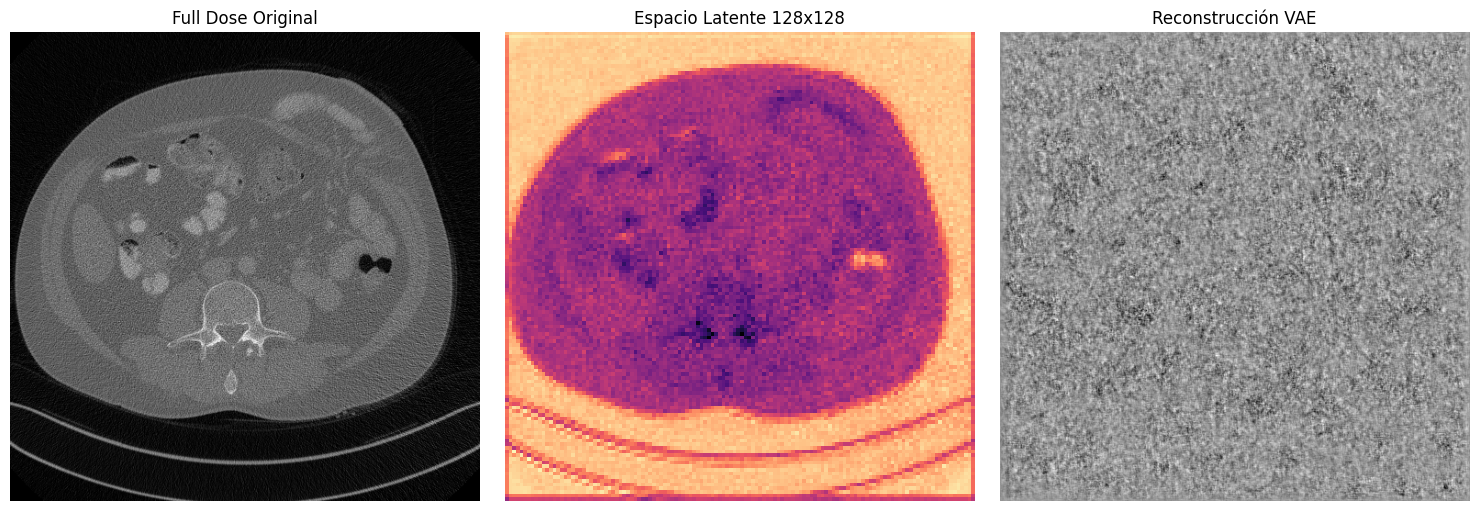

Dimensiones de entrada: torch.Size([1, 1, 512, 512])
Dimensiones latentes:  torch.Size([1, 4, 128, 128]) (Reducción 8x)
Dimensiones reconstrucción: torch.Size([1, 1, 512, 512])


In [26]:
import torch
import torch.nn as nn
from monai.networks.nets import AutoencoderKL
import matplotlib.pyplot as plt

# --- 1. Definir una función de normalización para el Dataset ---
def ct_normalization(full_img, low_img):
    """
    Normaliza el rango HU a [0, 1].
    Ajustamos de -1000 (aire) a 600 (tejido denso/hueso blando)
    para resaltar detalles anatómicos.
    """
    def scale(img):
        img = np.clip(img, -1000, 600)
        img = (img + 1000) / (600 + 1000)
        return img.astype(np.float32)
    
    return scale(full_img), scale(low_img)

# --- 2. Instanciar tu Dataset con la normalización ---
dataset = FullLowDosePairDataset(full_root, low_root)
loader = DataLoader(dataset, batch_size=1, shuffle=True, num_workers=4)

# --- 3. Configurar el AutoencoderKL de MONAI ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.empty_cache()

# --- 1. Definición de Arquitectura compatible con MedVAE ---
# Nota: MedVAE suele usar 128 canales base y 3 o 4 canales latentes.
model = AutoencoderKL(
    spatial_dims=2,
    in_channels=1,
    out_channels=1,
    channels=(128, 256, 512),   # Configuración estándar de MedVAE
    latent_channels=4,          # Verifica si tu versión usa 3 o 4
    num_res_blocks=2,
    attention_levels=(False, False, True),
).to(device)

batch = next(iter(loader))

model.eval()
inputs = batch["low"].to(device)
with torch.no_grad():
    reconstruction, mu, logvar = model(inputs)

# --- 5. Visualización de resultados ---
plt.figure(figsize=(15, 5))

# Imagen Original (Full Dose)
plt.subplot(1, 3, 1)
plt.title("Full Dose Original")
plt.imshow(inputs[0, 0].cpu(), cmap="gray")
plt.axis("off")

# Espacio Latente (Visualizando el primer canal de mu)
plt.subplot(1, 3, 2)
plt.title(f"Espacio Latente {mu.shape[2]}x{mu.shape[3]}")
plt.imshow(mu[0, 0].cpu(), cmap="magma")
plt.axis("off")

# Reconstrucción (Sin entrenar se verá ruido o gris)
plt.subplot(1, 3, 3)
plt.title("Reconstrucción VAE")
plt.imshow(reconstruction[0, 0].cpu(), cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Dimensiones de entrada: {inputs.shape}")
print(f"Dimensiones latentes:  {mu.shape} (Reducción 8x)")
print(f"Dimensiones reconstrucción: {reconstruction.shape}")

making attention of type 'vanilla' with 512 in_channels
Working with z of shape (1, 1, 128, 128) = 16384 dimensions.
making attention of type 'vanilla' with 512 in_channels
Restored from /home/klefur/.cache/huggingface/hub/models--stanfordmimi--MedVAE/snapshots/8040c5ccb7a51eff6b4cef513c7f20bd1bda983d/model_weights/vae_4x_1c_2D.ckpt with 0 missing and 0 unexpected keys
¡Modelo MVAE 2D cargado correctamente!
Dimensiones latentes:  torch.Size([1, 1, 128, 128]) (Reducción 8x)


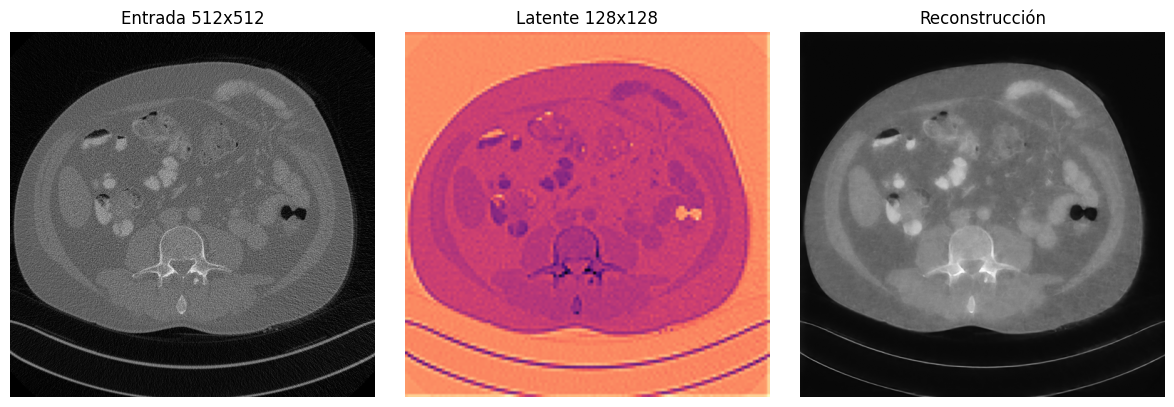

Dimensiones de entrada: torch.Size([1, 1, 512, 512])
Dimensiones latentes:  torch.Size([1, 1, 128, 128]) (Reducción 8x)
Dimensiones reconstrucción: torch.Size([1, 1, 512, 512])


In [27]:
import torch
from medvae import MVAE
import matplotlib.pyplot as plt

# --- 1. Configuración del dispositivo ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- 2. Carga del Modelo ---
# IMPORTANTE: Usamos modality="xray" para tener acceso al modelo 2D
try:
    model = MVAE(model_name="medvae_4_1_2d", modality="xray").to(device)
    model.requires_grad_(False)
    model.eval()
    print("¡Modelo MVAE 2D cargado correctamente!")
except Exception as e:
    print(f"Error al cargar MVAE: {e}")

with torch.no_grad():
    # 1. Obtener el latente
    latent = model.encode(inputs)
    print(f"Dimensiones latentes:  {latent.shape} (Reducción 8x)")
    # 2. SOLUCIÓN AL ERROR: Re-formatear el latente si perdió dimensiones
    # MedVAE suele usar 4 canales latentes (C=4). Ajustamos a 4D: [B, C, H, W]
    if latent.ndim == 2:
        # De [128, 128] a [1, 1, 128, 128] (si es 1 canal latente)
        latent = latent.reshape(1, 1, 128, 128)
        print("Latente reformateado a 4D con 1 canal.")
    elif latent.ndim == 3:
        # De [4, 128, 128] a [1, 4, 128, 128]
        latent = latent.unsqueeze(0)
        print("Latente reformateado a 4D con 4 canales.")
    
    # Asegurar que los canales coincidan con lo que el decoder espera
    # Si el log decía "Working with z of shape (1, 4, ...)", usa latent.reshape(1, 4, 128, 128)

    # 3. Decodificar
    reconstruction = model.decode(latent)

# --- 5. Visualización ---
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.title(f"Entrada {inputs.shape[2]}x{inputs.shape[3]}")
plt.imshow(inputs[0, 0].cpu(), cmap="gray")
plt.axis("off")

plt.subplot(1, 3, 2)
# Mostramos el primer canal del espacio latente
plt.title(f"Latente {latent.shape[2]}x{latent.shape[3]}")
plt.imshow(latent[0, 0].cpu(), cmap="magma")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title("Reconstrucción")
plt.imshow(reconstruction[0, 0].cpu(), cmap="gray")
plt.axis("off")

plt.tight_layout()
plt.show()

print(f"Dimensiones de entrada: {inputs.shape}")
print(f"Dimensiones latentes:  {latent.shape} (Reducción 8x)")
print(f"Dimensiones reconstrucción: {reconstruction.shape}")